# PRESELECCIÓN DE VARIABLES 

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import janitor
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import RFE
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## IMPORTAR LOS DATOS 

In [20]:
df = pd.read_pickle('../02_datos/03_Entrenamiento/df_tablon_transformado.pkl')

## MÉTODOS SUPERVISADOS 

### Preparar x e y

In [21]:
target = 'ventas'
x = df.drop(columns=['date', 'store_id', 'item_id', 'ventas']).copy()
y = df[target].copy()

### Mutual information

#### Crear una función para mostrar el resultado

In [24]:
def ranking_mi(mutual_selector, modo = 'tabla'):

    # Maquetar el ranking
    ranking_mi = pd.DataFrame(mutual_selector, index = x.columns).reset_index()
    ranking_mi.columns = ['variable', 'importancia_mi']
    ranking_mi = ranking_mi.sort_values( by = 'importancia_mi', ascending = False)
    ranking_mi['ranking_mi'] = np.arange(0, ranking_mi.shape[0])

    # Muestra la salida
    if modo == 'tabla':
        return(ranking_mi)
    else:
        g = ranking_mi.importancia_mi.sort_values().plot.barh(figsize=(12,20))
        g.set_yticklabels(ranking_mi.sort_values(by = 'importancia_mi').variable)
        return(g)

#### Calcular y revisar

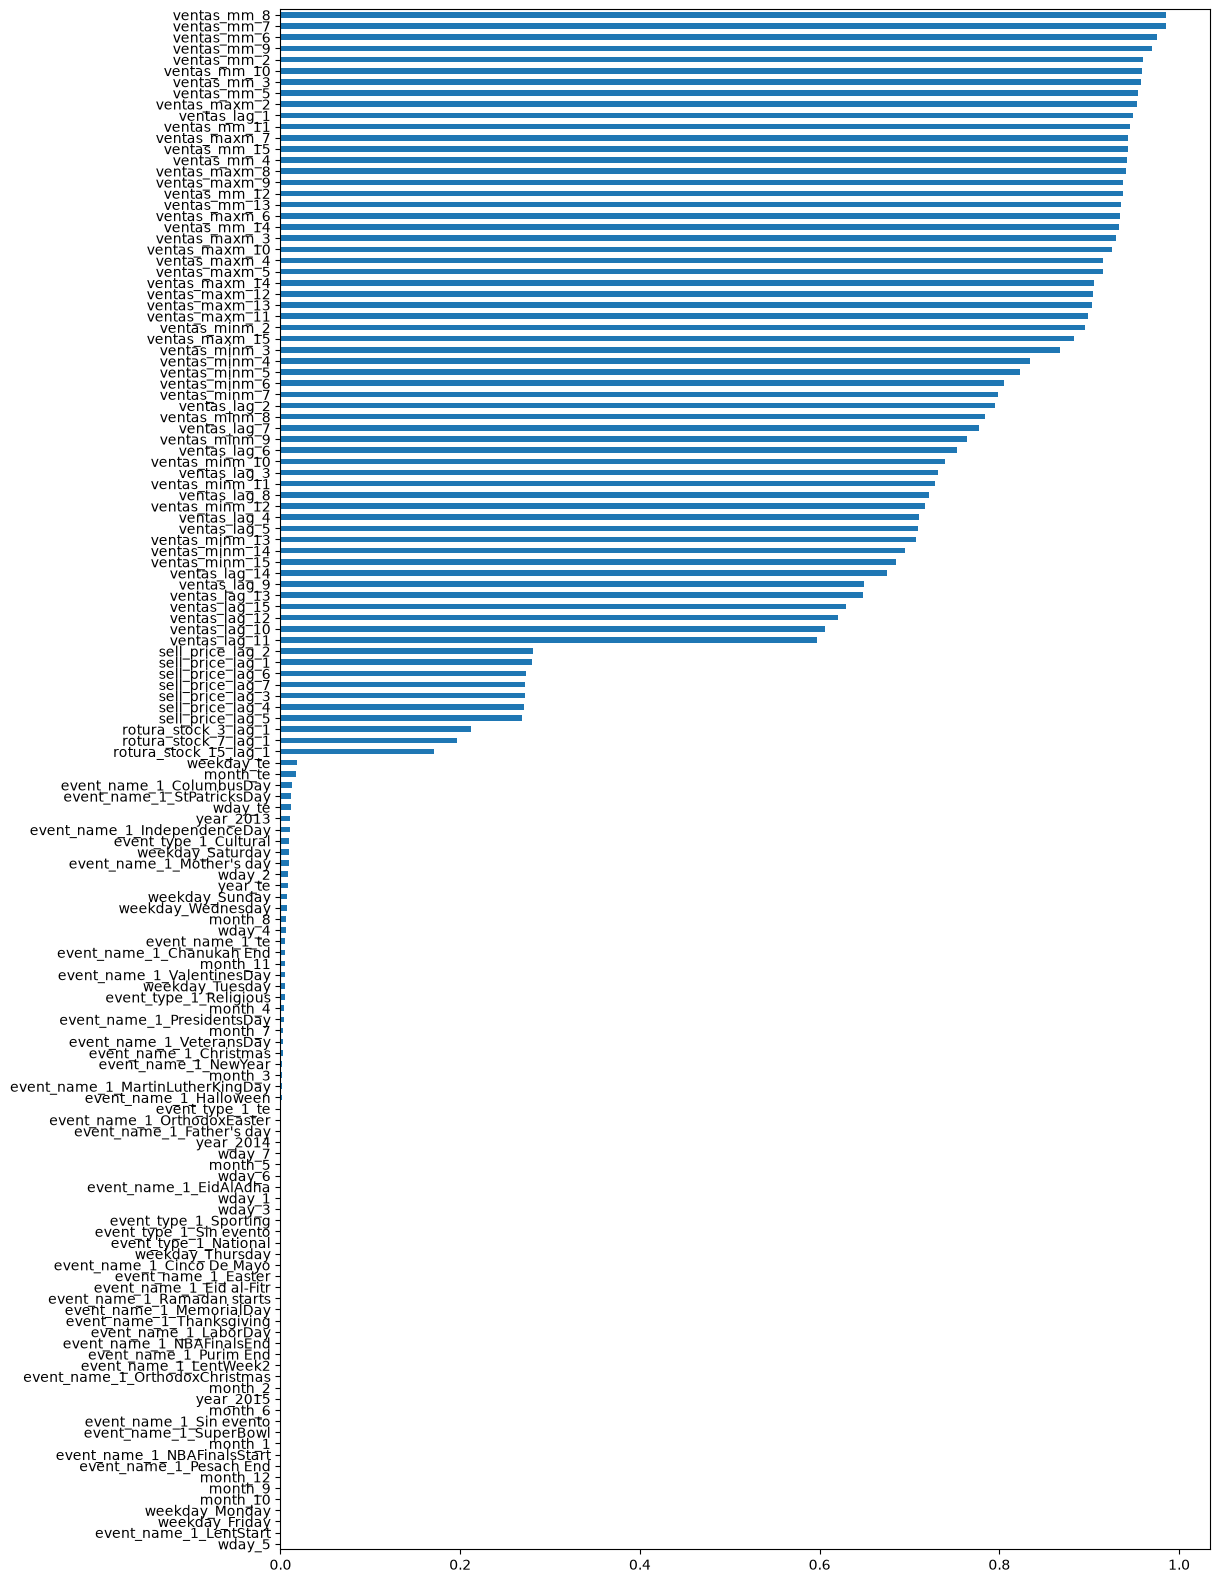

In [25]:
mutual_selector = mutual_info_regression(x, y)

rank_mi = ranking_mi(mutual_selector, modo = 'grafico')

#### Seleccionar las variables que pasan

##### Definir la posicion de la última variable que va a entrar

Miramos la posición de la última variable que queremos

In [26]:
ranking_mi(mutual_selector).reset_index().iloc[60:100]

,index,variable,importancia_mi,ranking_mi
60,77,sell_price_lag_7,0.272,60
61,73,sell_price_lag_3,0.272,61
62,74,sell_price_lag_4,0.271,62
63,75,sell_price_lag_5,0.269,63
64,78,rotura_stock_3_lag_1,0.212,64
65,79,rotura_stock_7_lag_1,0.196,65
66,80,rotura_stock_15_lag_1,0.171,66
67,68,weekday_te,0.019,67
68,66,month_te,0.018,68
69,37,event_name_1_ColumbusDay,0.013,69


In [27]:
posicion_variable_limite = 75

##### Extraer los nombres de las que entran

In [28]:
entran_mi = ranking_mi(mutual_selector).iloc[0:posicion_variable_limite].variable

##### Crear el dataframe con la selección

In [29]:
x_mi = x[entran_mi].copy()

## Recursive Feature Elimination

#### Instaciar

In [30]:
rfe = RFE(estimator = XGBRegressor(n_jobs = -1, eval_metrics='mae'))

### Entrenar

In [31]:
rfe.fit(x,y)

c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\xgboost\training.py:200: UserWarning: [12:59:43] WARNING: C:\Users\task_179016205368646\croot\xgboost-split_1790162376793\work\src\learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\xgboost\training.py:200: UserWarning: [12:59:45] WARNING: C:\Users\task_179016205368646\croot\xgboost-split_1790162376793\work\src\learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\xgboost\training.py:200: UserWarning: [12:59:46] WARNING: C:\Users\task_179016205368646\croot\xgboost-split_1790162376793\work\src\learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\phdel\miniconda3\envs\ForecastingRetail\Lib\site-packages\xgboost\training.p

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).","XGBRegressor(..._jobs=-1, ...)"
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",None
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,XGBRegressor,"XGBRegressor(..._jobs=-1, ...)"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](138,)","['year_2013','year_2014','year_2015',...,'ventas_maxm_13','ventas_maxm_14', 'ventas_maxm_15']"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(69)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,138
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](138,)","[25,32,19,..., 4, 1, 1]"


#### Extraer los nombres de las variables 

In [32]:
entran_rfe = x.columns[rfe.support_]

In [33]:
entran_rfe

Index(['month_3', 'month_11', 'month_12', 'wday_1', 'wday_2', 'wday_3',
       'event_name_1_Christmas', 'event_name_1_Thanksgiving', 'wday_te',
       'event_name_1_te', 'sell_price_lag_1', 'sell_price_lag_2',
       'sell_price_lag_3', 'sell_price_lag_5', 'sell_price_lag_6',
       'sell_price_lag_7', 'ventas_lag_1', 'ventas_lag_2', 'ventas_lag_3',
       'ventas_lag_4', 'ventas_lag_5', 'ventas_lag_6', 'ventas_lag_7',
       'ventas_lag_8', 'ventas_lag_9', 'ventas_lag_10', 'ventas_lag_11',
       'ventas_lag_12', 'ventas_lag_13', 'ventas_lag_14', 'ventas_lag_15',
       'ventas_minm_2', 'ventas_minm_3', 'ventas_minm_4', 'ventas_minm_5',
       'ventas_minm_6', 'ventas_minm_7', 'ventas_minm_9', 'ventas_minm_10',
       'ventas_minm_11', 'ventas_minm_13', 'ventas_minm_14', 'ventas_minm_15',
       'ventas_mm_2', 'ventas_mm_3', 'ventas_mm_4', 'ventas_mm_6',
       'ventas_mm_7', 'ventas_mm_8', 'ventas_mm_9', 'ventas_mm_10',
       'ventas_mm_11', 'ventas_mm_12', 'ventas_mm_13', 'ventas_

### Crear el dataframe con la selección

In [34]:
x_rfe = x[entran_rfe].copy()

## Permutation Importance

### Crear una funcion para mostrar el resultado

In [47]:
def ranking_per(predictoras, permutacion):
    ranking_per = pd.DataFrame({'variable': predictoras.columns, 'importancia_per': permutacion.importances_mean})
    ranking_per = ranking_per.sort_values(by = 'importancia_per', ascending=False)
    ranking_per['ranking_per'] = np.arange(0, ranking_per.shape[0])

    return(ranking_per)

### Instanciar y entrenar

In [48]:
xgb = XGBRegressor(n_jobs = -1, eval_metric='mae')

xgb.fit(x,y)

permutacion = permutation_importance(xgb,
                                     x, y,
                                     scoring = 'neg_mean_absolute_percentage_error',
                                     n_repeats = 3, n_jobs = -1)

### Revisar la salida

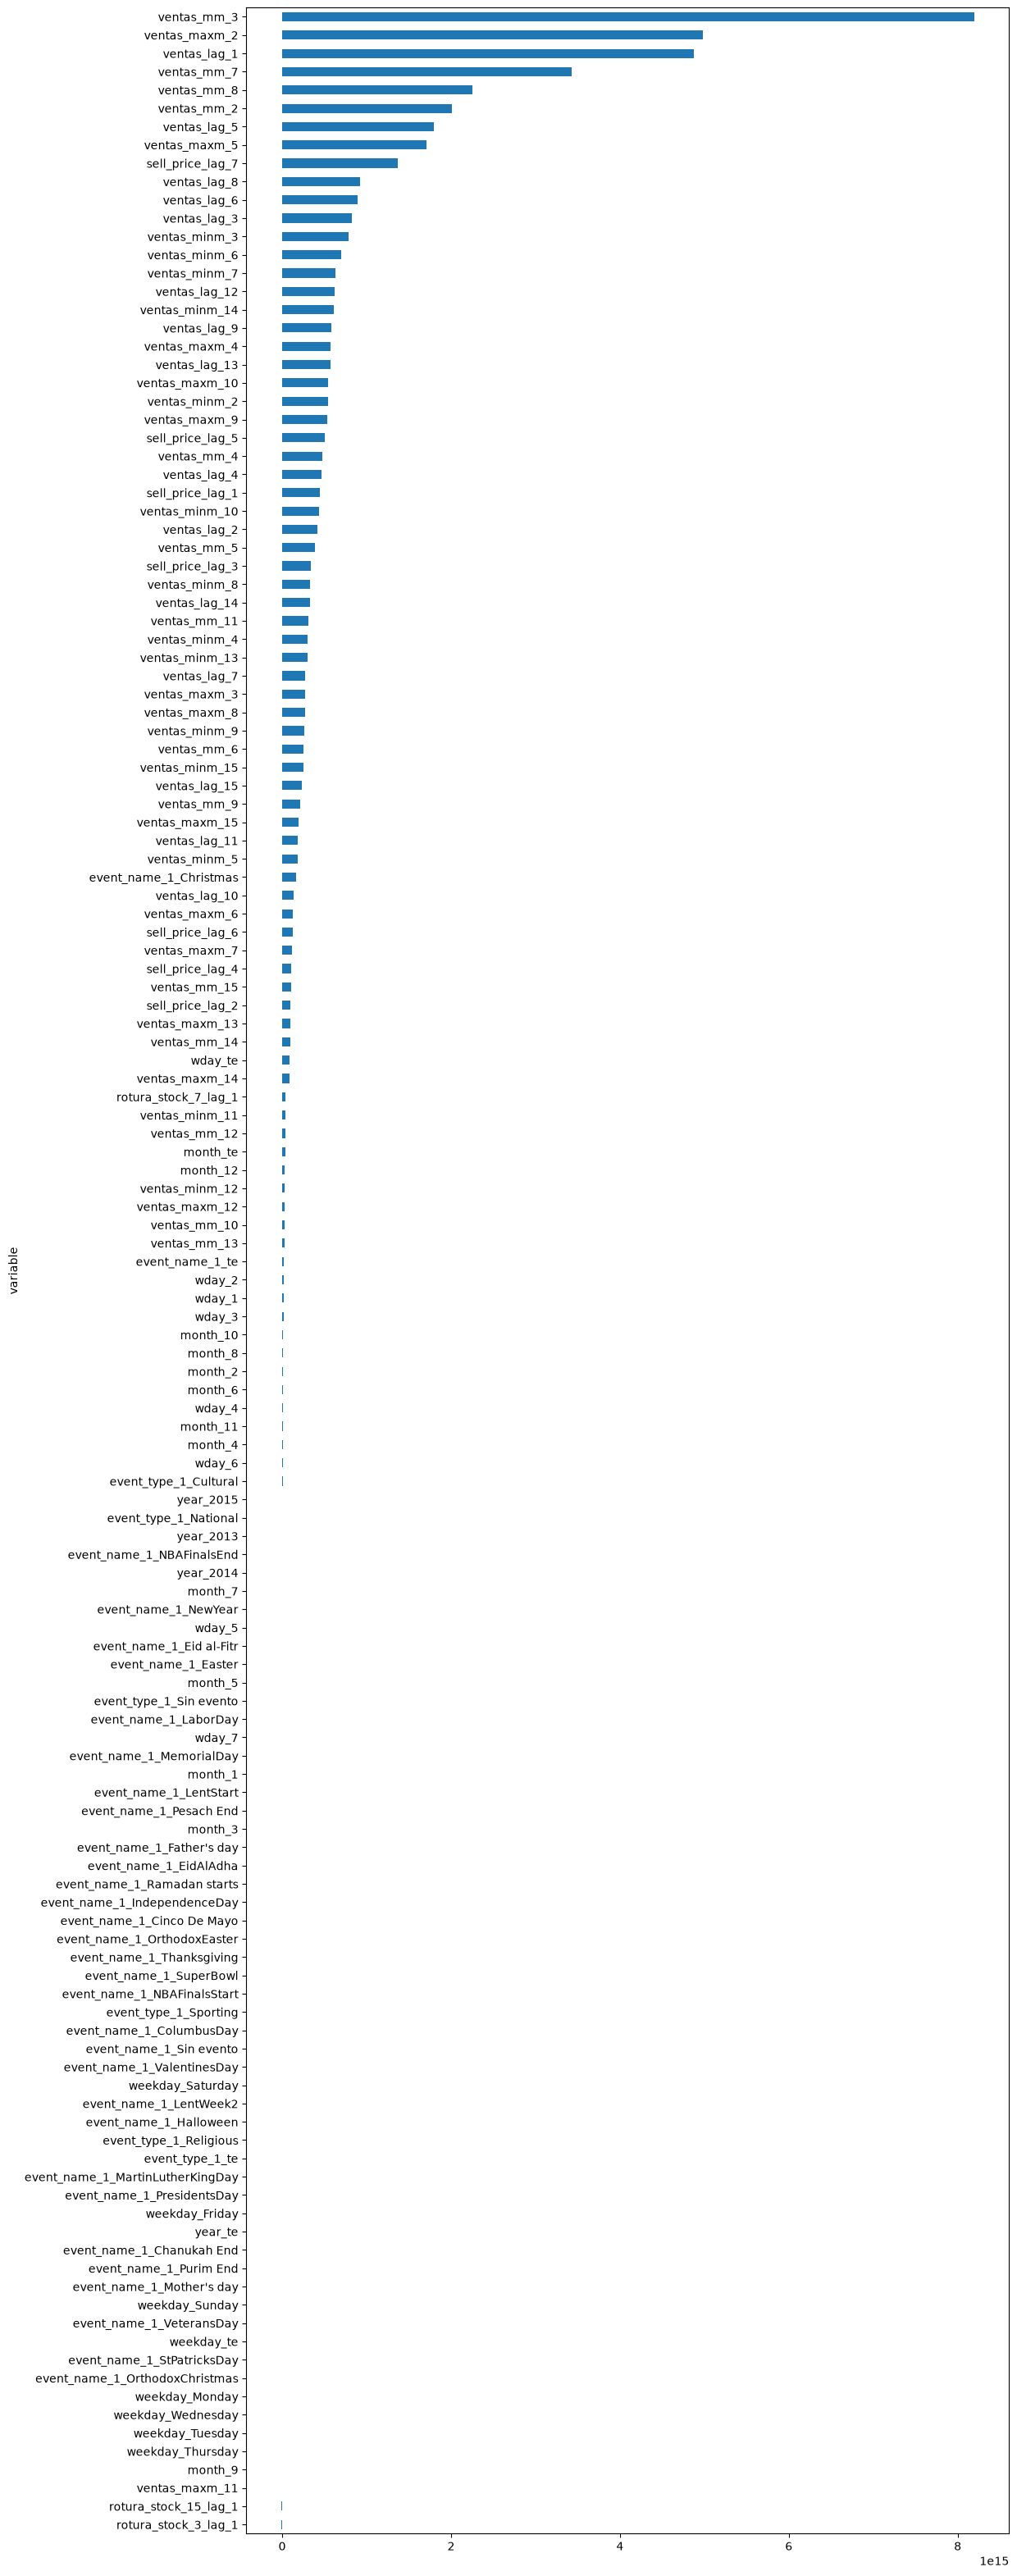

In [49]:
rank_per = ranking_per(x, permutacion)

rank_per.set_index('variable').importancia_per.sort_values().plot.barh(figsize = (12,40));

### Seleccionar las variables que pasan

#### Definir la posición de la última variable que va a entrar

In [50]:
rank_per.reset_index().iloc[50:100]

,index,variable,importancia_per,ranking_per
50,76,sell_price_lag_6,121514691133440.000,50
51,129,ventas_maxm_7,114342453663061.328,51
52,74,sell_price_lag_4,110833107468288.000,52
53,123,ventas_mm_15,102412824084480.000,53
54,72,sell_price_lag_2,100220019583658.672,54
55,135,ventas_maxm_13,99842330897066.672,55
56,122,ventas_mm_14,96104680346965.328,56
57,67,wday_te,84728967331840.000,57
58,136,ventas_maxm_14,83724705551701.328,58
59,79,rotura_stock_7_lag_1,39157664230058.664,59


In [51]:
posicion_variable_limite = 74

#### Extraer el nombre de las que entran

In [52]:
entran_per = rank_per.iloc[0:posicion_variable_limite].variable

#### Crear el dataframe con la selección

In [53]:
x_per = x[entran_per].copy()

## SELECCIONAR EL MÉTODO FINAL

In [54]:
x_preseleccionado = x_mi
#x_preseleccionado = x_rfe
#x_preseleccionado = x_per

## INCORPORACIÓN DE VARIABLES DE SEGMENTACIÓN

Vamos a añadir las variables de segmentacion que tambien necesitaremos 

In [56]:
x_preseleccionado = pd.concat([df[['date', 'store_id', 'item_id']], x_preseleccionado], axis=1)

In [60]:
x_preseleccionado.to_pickle('../02_datos/03_Entrenamiento/x_preseleccionado.pkl')
y_preseleccionado = pd.DataFrame({'ventas':y.copy()})
y_preseleccionado.to_pickle('../02_datos/03_Entrenamiento/y_preseleccionado.pkl')